## Подключение библиотек

In [1]:
# Остновные библиотеки
import os
import cv2
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
from typing import Optional, Tuple, List


# Torch
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

# Sceletons
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

## Подготовка датасетов

In [2]:
class SkeletonExtractor:
    def __init__(self, model_complexity=1, device='CPU', models_dir=None):
        """
        Инициализация MediaPipe Pose с использованием Tasks API
        
        Args:
            model_complexity: 0=легкий, 1=средний, 2=тяжелый
            device: 'CPU' или 'GPU' (если доступно)
            models_dir: путь к директории с моделями
        """
        # Определяем имя файла модели в зависимости от сложности
        model_files = {
            0: "pose_landmarker_lite.task",
            1: "pose_landmarker_full.task", 
            2: "pose_landmarker_heavy.task"
        }

        model_path = os.path.join(models_dir, model_files[model_complexity])
        
        # Проверяем существование файла
        if not os.path.exists(model_path):
            raise FileNotFoundError(f"Файл модели не найден: {model_path}")
        
        print(f"Используется модель: {model_files[model_complexity]}")
        
        # Настройка базовых опций
        if device.upper() == 'GPU':
            try:
                base_options = python.BaseOptions(
                    model_asset_path=model_path,
                    delegate=python.BaseOptions.Delegate.GPU
                )
                print("Используется GPU ускорение")
            except Exception as e:
                print(f"GPU delegate не доступен, используем CPU: {e}")
                base_options = python.BaseOptions(
                    model_asset_path=model_path,
                    delegate=python.BaseOptions.Delegate.CPU
                )
        else:
            base_options = python.BaseOptions(
                model_asset_path=model_path,
                delegate=python.BaseOptions.Delegate.CPU
            )
            print("Используется CPU")
        
        # Настройка опций PoseLandmarker
        options = vision.PoseLandmarkerOptions(
            base_options=base_options,
            running_mode=vision.RunningMode.VIDEO,
            num_poses=1,  # Только одна поза на кадр
            min_pose_detection_confidence=0.5,
            min_pose_presence_confidence=0.5,
            min_tracking_confidence=0.5,
            output_segmentation_masks=False
        )
        
        # Создаем landmarker
        try:
            self.landmarker = vision.PoseLandmarker.create_from_options(options)
            print("PoseLandmarker успешно инициализирован")
        except Exception as e:
            raise RuntimeError(f"Ошибка инициализации PoseLandmarker: {e}")
        
        # 33 ключевые точки MediaPipe Pose
        self.num_joints = 33
        self.joint_names = [
            'nose', 'left_eye_inner', 'left_eye', 'left_eye_outer',
            'right_eye_inner', 'right_eye', 'right_eye_outer',
            'left_ear', 'right_ear', 'mouth_left', 'mouth_right',
            'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow',
            'left_wrist', 'right_wrist', 'left_pinky', 'right_pinky',
            'left_index', 'right_index', 'left_thumb', 'right_thumb',
            'left_hip', 'right_hip', 'left_knee', 'right_knee',
            'left_ankle', 'right_ankle', 'left_heel', 'right_heel',
            'left_foot_index', 'right_foot_index'
        ]
        
        # Соединения для визуализации
        self.connections = [
            (0, 1), (1, 2), (2, 3), (3, 7), (0, 4), (4, 5),
            (5, 6), (6, 8), (9, 10), (11, 12), (11, 13),
            (13, 15), (15, 17), (15, 19), (15, 21), (17, 19),
            (12, 14), (14, 16), (16, 18), (16, 20), (16, 22),
            (18, 20), (11, 23), (12, 24), (23, 24), (23, 25),
            (24, 26), (25, 27), (26, 28), (27, 29), (28, 30),
            (29, 31), (30, 32), (27, 31), (28, 32)
        ]
    
    def extract_from_video(self, video_path: str, max_frames: Optional[int] = None, 
                          sample_rate: int = 1, target_fps: Optional[float] = None) -> Tuple[Optional[np.ndarray], List[int]]:
        """
        Извлекает скелеты из видео файла
        
        Args:
            video_path: путь к видео
            max_frames: максимальное количество кадров (None = все)
            sample_rate: брать каждый n-й кадр
            target_fps: целевая частота кадров (если None, используется исходная)
        
        Returns:
            keypoints: [T, 33, 3] - x, y, visibility для каждого кадра
            frame_indices: индексы обработанных кадров
        """
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            print(f"Ошибка открытия видео: {video_path}")
            return None, []
        
        # Получаем информацию о видео
        original_fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        # Используем target_fps если указан, иначе исходную
        fps = target_fps if target_fps is not None else original_fps
        frame_interval = int(original_fps / fps) if fps < original_fps else 1
        
        if max_frames:
            total_frames = min(total_frames, max_frames * frame_interval)
        
        print(f"Видео: {Path(video_path).name}")
        print(f"  Оригинальный FPS: {original_fps:.1f}, Целевой FPS: {fps:.1f}")
        print(f"  Кадров: {total_frames}, Интервал: {frame_interval}")
        
        keypoints_list = []
        frame_indices = []
        frame_count = 0
        processed_frames = 0
        
        with tqdm(total=total_frames // frame_interval, desc="Извлечение скелетов") as pbar:
            while frame_count < total_frames:
                ret, frame = cap.read()
                if not ret:
                    break
                
                # Пропускаем кадры согласно интервалу
                if frame_count % frame_interval != 0:
                    frame_count += 1
                    continue
                
                # Дополнительная проверка sample_rate
                if processed_frames % sample_rate != 0:
                    processed_frames += 1
                    frame_count += 1
                    continue
                
                # Конвертируем BGR в RGB
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame_rgb = np.ascontiguousarray(frame_rgb)
                
                # Создаем MediaPipe Image
                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=frame_rgb
                )
                
                # Рассчитываем временную метку в миллисекундах
                timestamp_ms = int((frame_count / original_fps) * 1000)
                
                # Обработка кадра MediaPipe
                detection_result = self.landmarker.detect_for_video(mp_image, timestamp_ms)
                
                if detection_result.pose_landmarks and len(detection_result.pose_landmarks) > 0:
                    # Берем первую (и единственную) позу
                    landmarks = detection_result.pose_landmarks[0]
                    
                    # Извлекаем координаты 33 точек
                    frame_keypoints = []
                    for landmark in landmarks:
                        # x, y, z - нормализованные [0, 1]
                        frame_keypoints.append([
                            landmark.x,
                            landmark.y,
                            landmark.z,
                            landmark.visibility if hasattr(landmark, 'visibility') else 1.0
                        ])
                    
                    keypoints_list.append(frame_keypoints)
                    frame_indices.append(frame_count)
                else:
                    # Если поза не обнаружена, заполняем нулями
                    keypoints_list.append([[0, 0, 0, 0] for _ in range(self.num_joints)])
                    frame_indices.append(frame_count)
                
                processed_frames += 1
                frame_count += 1
                pbar.update(1)
                
                # Прерываем если достигли max_frames
                if max_frames and processed_frames >= max_frames:
                    break
        
        cap.release()
        
        if not keypoints_list:
            print(f"Не удалось извлечь скелеты из {video_path}")
            return None, []
        
        keypoints_array = np.array(keypoints_list, dtype=np.float32)  # [T, 33, 4]
        print(f"  Извлечено: {keypoints_array.shape[0]} кадров")
        
        return keypoints_array, frame_indices
    
    def extract_from_frames(self, frames: List[np.ndarray]) -> Optional[np.ndarray]:
        """
        Извлекает скелеты из списка кадров
        
        Args:
            frames: список кадров в формате BGR или RGB
            
        Returns:
            keypoints: [T, 33, 4] - x, y, z, visibility для каждого кадра
        """
        keypoints_list = []
        
        for i, frame in enumerate(tqdm(frames, desc="Извлечение скелетов")):
            # Если кадр в BGR, конвертируем в RGB
            if len(frame.shape) == 3 and frame.shape[2] == 3:
                # Проверяем, не RGB ли уже
                if frame[0, 0, 0] > frame[0, 0, 2]:  # Если B > R, вероятно BGR
                    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                else:
                    frame_rgb = frame.copy()
            else:
                frame_rgb = frame.copy()
            
            frame_rgb = np.ascontiguousarray(frame_rgb)
            
            # Создаем MediaPipe Image
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=frame_rgb
            )
            
            # Рассчитываем временную метку (для изображений можно использовать 0)
            timestamp_ms = i * 33  # Примерная временная метка
            
            # Обработка кадра MediaPipe
            detection_result = self.landmarker.detect_for_video(mp_image, timestamp_ms)
            
            if detection_result.pose_landmarks and len(detection_result.pose_landmarks) > 0:
                landmarks = detection_result.pose_landmarks[0]
                
                frame_keypoints = []
                for landmark in landmarks:
                    frame_keypoints.append([
                        landmark.x,
                        landmark.y,
                        landmark.z,
                        landmark.visibility if hasattr(landmark, 'visibility') else 1.0
                    ])
                
                keypoints_list.append(frame_keypoints)
            else:
                keypoints_list.append([[0, 0, 0, 0] for _ in range(self.num_joints)])
        
        if not keypoints_list:
            return None
        
        return np.array(keypoints_list, dtype=np.float32)
    
    def visualize_skeleton(self, frame: np.ndarray, keypoints: np.ndarray, 
                          thickness: int = 2, circle_radius: int = 3) -> np.ndarray:
        """
        Рисует скелет на кадре
        
        Args:
            frame: входной кадр (BGR или RGB)
            keypoints: массив [33, 4] с координатами точек
            thickness: толщина линий
            circle_radius: радиус точек
            
        Returns:
            output_frame: кадр с нарисованным скелетом
        """
        if frame.shape[2] == 3 and frame[0, 0, 0] > frame[0, 0, 2]:  # BGR
            output_frame = frame.copy()
        else:  # RGB или другое
            output_frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR) if len(frame.shape) == 3 else frame
        
        h, w = output_frame.shape[:2]
        
        # Преобразуем нормализованные координаты в пиксели
        pixel_points = []
        for kp in keypoints:
            x, y = int(kp[0] * w), int(kp[1] * h)
            pixel_points.append((x, y))
        
        # Рисуем кости
        for start_idx, end_idx in self.connections:
            if start_idx < len(pixel_points) and end_idx < len(pixel_points):
                start_point = pixel_points[start_idx]
                end_point = pixel_points[end_idx]
                
                # Рисуем линию только если обе точки валидны
                if (0 <= start_point[0] < w and 0 <= start_point[1] < h and
                    0 <= end_point[0] < w and 0 <= end_point[1] < h and
                    keypoints[start_idx][3] > 0.1 and keypoints[end_idx][3] > 0.1):
                    
                    cv2.line(output_frame, start_point, end_point, (0, 255, 0), thickness)
        
        # Рисуем точки
        for i, point in enumerate(pixel_points):
            if (0 <= point[0] < w and 0 <= point[1] < h and 
                keypoints[i][3] > 0.1):
                cv2.circle(output_frame, point, circle_radius, (0, 0, 255), -1)
                # Подписываем точки (опционально)
                # cv2.putText(output_frame, str(i), point, cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 255, 255), 1)
        
        return output_frame
    
    def save_keypoints(self, keypoints: np.ndarray, output_path: str):
        """
        Сохраняет ключевые точки в файл
        
        Args:
            keypoints: массив ключевых точек
            output_path: путь для сохранения
        """
        np.save(output_path, keypoints)
        print(f"Ключевые точки сохранены в {output_path}")
    
    def load_keypoints(self, input_path: str) -> np.ndarray:
        """
        Загружает ключевые точки из файла
        
        Args:
            input_path: путь к файлу
            
        Returns:
            keypoints: массив ключевых точек
        """
        keypoints = np.load(input_path)
        print(f"Загружено ключевых точек: {keypoints.shape}")
        return keypoints
    
    def __del__(self):
        """Очистка ресурсов"""
        if hasattr(self, 'landmarker'):
            del self.landmarker

In [ ]:
class SkeletonDataset:
    def __init__(self, ucf101_csv, video_root, output_dir="./skeleton_data", 
                 model_complexity=1, device='CPU', models_dir=None):
        """
        Создает датасет скелетов из UCF101
        
        Args:
            ucf101_csv: путь к CSV файлу UCF101
            video_root: корневая директория с видео
            output_dir: директория для сохранения скелетов
            model_complexity: сложность модели MediaPipe (0=легкий, 1=средний, 2=тяжелый)
            device: 'CPU' или 'GPU'
            models_dir: путь к директории с моделями
        """
        self.csv_path = ucf101_csv
        self.video_root = video_root
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)
        
        # Загружаем CSV
        self.df = pd.read_csv(ucf101_csv)
        
        print(f"Загружено строк из CSV: {len(self.df)}")
        print("Пример данных:")
        print(self.df.head())
        
        # Фильтруем существующие видео
        self.df = self._filter_existing_videos()
        
        if len(self.df) == 0:
            raise ValueError(f"Не найдено ни одного видео в {video_root}")
        
        # Создаем mapping классов
        self.classes = sorted(self.df['label'].unique())
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}
        self.idx_to_class = {idx: cls for idx, cls in enumerate(self.classes)}
        
        print(f"Классы: {len(self.classes)}")
        print(f"Доступные видео после фильтрации: {len(self.df)}")
        
        # Инициализируем экстрактор
        print(f"Инициализация экстрактора с моделью сложности {model_complexity}...")
        self.extractor = SkeletonExtractor(
            model_complexity=model_complexity,
            device=device,
            models_dir=models_dir
        )
    
    def _filter_existing_videos(self):
        """Фильтрует только существующие видео файлы"""
        existing_videos = []
        
        print(f"Проверка существования видео в {self.video_root}...")
        
        for idx, row in self.df.iterrows():
            clip_path = row['clip_path']
            
            # Убираем начальный слеш если есть
            if clip_path.startswith('/'):
                clip_path = clip_path[1:]
            
            # Формируем полный путь
            full_path = Path(self.video_root) / clip_path
            
            # Проверяем существование файла
            if full_path.exists():
                existing_videos.append(row)
            else:
                print(f"  Файл не найден: {full_path}")
                
                # Пробуем найти файл без учета регистра
                possible_files = list(Path(self.video_root).rglob(Path(clip_path).name))
                if possible_files:
                    print(f"  Найден похожий файл: {possible_files[0]}")
                    # Можем использовать первый найденный
                    row['clip_path'] = str(possible_files[0].relative_to(self.video_root))
                    existing_videos.append(row)
        
        print(f"Найдено существующих видео: {len(existing_videos)}")
        return pd.DataFrame(existing_videos, columns=self.df.columns)
    
    def _get_safe_filename(self, video_path, class_name, idx):
        """Создает безопасное имя файла для сохранения"""
        video_stem = Path(video_path).stem
        
        # Ограничиваем длину имени
        if len(video_stem) > 50:
            video_stem = video_stem[:50]
        
        # Убираем специальные символы
        safe_stem = ''.join(c for c in video_stem if c.isalnum() or c in ('_', '-'))
        class_safe = ''.join(c for c in class_name if c.isalnum() or c in ('_', '-'))
        
        return f"{class_safe}_{idx:04d}_{safe_stem}.npy"
    
    def process_dataset(self, max_videos_per_class=None, max_frames=150, 
                       sample_rate=2, skip_existing=True, force_reprocess=False):
        """
        Обрабатывает весь датасет и сохраняет скелеты
        
        Args:
            max_videos_per_class: максимальное количество видео на класс
            max_frames: максимальное количество кадров для обработки
            sample_rate: частота семплирования кадров
            skip_existing: пропускать уже обработанные файлы
            force_reprocess: перезаписать существующие файлы
        """
        skeletons = []
        labels = []
        video_paths = []
        processed_count = 0
        skipped_count = 0
        error_count = 0
        
        # Проверяем существующие метаданные
        metadata_file = self.output_dir / "metadata.pkl"
        existing_files = set()
        
        if metadata_file.exists() and skip_existing and not force_reprocess:
            print("Найдены существующие метаданные. Загружаем...")
            try:
                with open(metadata_file, 'rb') as f:
                    existing_metadata = pickle.load(f)
                existing_files = set(existing_metadata.get('skeletons', []))
                print(f"Загружено {len(existing_files)} существующих записей")
            except Exception as e:
                print(f"Ошибка загрузки метаданных: {e}")
        
        # Счетчик для общего прогресса
        total_videos = sum(min(len(self.df[self.df['label'] == cls]), 
                             max_videos_per_class or len(self.df)) 
                         for cls in self.classes)
        print(f"Всего видео для обработки: {total_videos}")
        
        # Группируем по классам
        for class_idx, class_name in enumerate(tqdm(self.classes, desc="Обработка классов")):
            class_videos = self.df[self.df['label'] == class_name]
            
            # Ограничиваем количество видео на класс
            if max_videos_per_class:
                class_videos = class_videos.head(max_videos_per_class)
            
            print(f"\nОбработка класса '{class_name}' ({len(class_videos)} видео)")
            
            # Создаем директорию для класса
            class_dir = self.output_dir / class_name
            class_dir.mkdir(exist_ok=True)
            
            # Проходим по видео класса
            for video_idx, (_, row) in enumerate(tqdm(class_videos.iterrows(), 
                                                     desc=f"Видео класса {class_name}", 
                                                     leave=False)):
                clip_path = row['clip_path']
                
                # Убираем начальный слеш если есть
                if clip_path.startswith('/'):
                    clip_path = clip_path[1:]
                
                # Формируем полный путь
                full_path = Path(self.video_root) / clip_path
                
                if not full_path.exists():
                    print(f"  Файл не существует: {full_path}")
                    error_count += 1
                    continue
                
                # Генерируем имя для сохранения
                save_name = self._get_safe_filename(clip_path, class_name, video_idx)
                save_path = class_dir / save_name
                
                # Относительный путь для метаданных
                relative_save_path = str(save_path.relative_to(self.output_dir))
                
                # Пропускаем если уже обработано
                if relative_save_path in existing_files and skip_existing and not force_reprocess:
                    if save_path.exists():  # Дополнительная проверка существования файла
                        skeletons.append(relative_save_path)
                        labels.append(class_idx)
                        video_paths.append(str(full_path))
                        skipped_count += 1
                        continue
                
                try:
                    print(f"  Обработка {full_path.name}...")
                    
                    # Извлекаем скелет
                    keypoints, _ = self.extractor.extract_from_video(
                        str(full_path),
                        max_frames=max_frames,
                        sample_rate=sample_rate,
                        target_fps=15
                    )
                    
                    if keypoints is not None and len(keypoints) >= 5:
                        # Сохраняем
                        np.save(save_path, keypoints)
                        
                        skeletons.append(relative_save_path)
                        labels.append(class_idx)
                        video_paths.append(str(full_path))
                        processed_count += 1
                        
                        if processed_count % 5 == 0:
                            print(f"\nПрогресс: обработано {processed_count}, пропущено {skipped_count}, ошибок {error_count}")
                    else:
                        if keypoints is None:
                            print(f"  Не удалось извлечь ключевые точки из {full_path.stem}")
                        else:
                            print(f"  Слишком мало ключевых точек в {full_path.stem}: {len(keypoints)}")
                        error_count += 1
                        
                except Exception as e:
                    print(f"\n  Ошибка обработки {full_path}: {e}")
                    import traceback
                    traceback.print_exc()
                    error_count += 1
                    continue
        
        # Сохраняем метаданные
        metadata = {
            'skeletons': skeletons,
            'labels': labels,
            'video_paths': video_paths,
            'class_to_idx': self.class_to_idx,
            'idx_to_class': self.idx_to_class,
            'output_dir': str(self.output_dir),
            'num_classes': len(self.classes),
            'num_samples': len(skeletons),
            'timestamp': pd.Timestamp.now()
        }
        
        try:
            with open(metadata_file, 'wb') as f:
                pickle.dump(metadata, f)
            print(f"\nМетаданные сохранены в {metadata_file}")
        except Exception as e:
            print(f"\nОшибка сохранения метаданных: {e}")
        
        print(f"\n{'='*60}")
        print("ОБРАБОТКА ЗАВЕРШЕНА!")
        print(f"  Всего доступно видео: {len(self.df)}")
        print(f"  Успешно обработано: {processed_count}")
        print(f"  Пропущено (уже обработанных): {skipped_count}")
        print(f"  Ошибок обработки: {error_count}")
        print(f"  Итого сохранено скелетов: {len(skeletons)}")
        print(f"  Выходная директория: {self.output_dir}")
        
        if len(skeletons) == 0:
            print("\nВНИМАНИЕ: Не сохранено ни одного скелета!")
            print("Возможные причины:")
            print("1. Все видео уже были обработаны и пропущены")
            print("2. Ошибки при извлечении ключевых точек")
            print("3. Проблемы с путями к видео файлам")
        
        return metadata

Используется модель: pose_landmarker_full.task
Используется CPU
PoseLandmarker успешно инициализирован
Видео: v_Archery_g02_c01.avi
  Оригинальный FPS: 25.0, Целевой FPS: 10.0
  Кадров: 158, Интервал: 2


Извлечение скелетов: 100%|██████████| 79/79 [00:01<00:00, 46.46it/s]


  Извлечено: 79 кадров
Извлечено ключевых точек: (79, 33, 4)


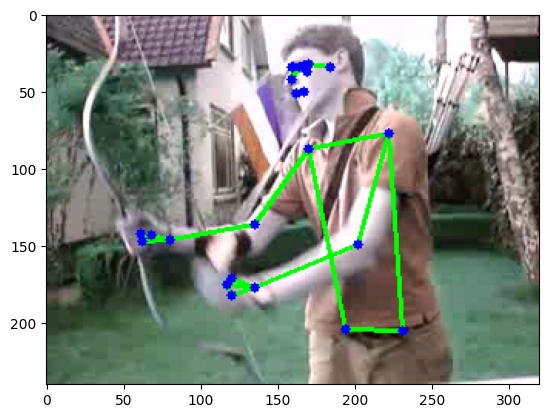

In [5]:
extractor = SkeletonExtractor(model_complexity=1, device='CPU', models_dir='../models/sceletons')
    
# Извлечение скелетов из видео
video_path = "../data/UCF101/test/Archery/v_Archery_g02_c01.avi"
keypoints, frame_indices = extractor.extract_from_video(
    video_path=video_path,
    max_frames=100,  # только первые 100 кадров
    sample_rate=1,
    target_fps=10  # снижаем FPS для ускорения
)
    
if keypoints is not None:
    print(f"Извлечено ключевых точек: {keypoints.shape}")
        
    # Сохранение результатов
    output_path = "keypoints.npy"
    # extractor.save_keypoints(keypoints, output_path)
        
    # Визуализация (пример для первого кадра)
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_indices[0])
    ret, frame = cap.read()
    cap.release()
        
    if ret:
        visualized_frame = extractor.visualize_skeleton(frame, keypoints[0])
        plt.imshow(visualized_frame)

In [1]:
# Обработка датасета
skeleton_dataset = SkeletonDataset(
    ucf101_csv='../data/UCF101/train.csv',
    video_root='../data/UCF101',
    output_dir='../data/skeletons',
    model_complexity=1,
    device='CPU',
    models_dir='../models/sceletons'
)

# Обработка
metadata = skeleton_dataset.process_dataset(
    max_videos_per_class=10,  # по 10 видео на класс
    max_frames=150,           # максимум 150 кадров
    sample_rate=2,            # каждый 2-й кадр
    skip_existing=True        # пропускать уже обработанные
)

NameError: name 'SkeletonDataset' is not defined

In [7]:
# Загрузка позже
loaded_dataset = SkeletonDataset.load_from_metadata('../data/skeletons/metadata.pkl')

# Получение данных
skeleton, label, video_path = loaded_dataset.get_sample(0)
print(f"Размер скелета: {skeleton.shape}")  # [T, 33, 4]
print(f"Метка: {loaded_dataset.idx_to_class[label]}")

Размер скелета: (50, 33, 4)
Метка: ApplyEyeMakeup


In [2]:
class SkeletonExtractor:
    def __init__(self, model_complexity=1):
        """Инициализация MediaPipe Pose"""
        self.mp_pose = mp.solutions.pose
        self.pose = self.mp_pose.Pose(
            static_image_mode=False,  # Для видео
            model_complexity=model_complexity,  # 0=легкий, 1=средний, 2=тяжелый
            smooth_landmarks=True,
            enable_segmentation=False,
            smooth_segmentation=True,
            min_detection_confidence=0.5,
            min_tracking_confidence=0.5
        )
        
        # 33 ключевые точки MediaPipe Pose
        self.num_joints = 33
        self.joint_names = [
            'nose', 'left_eye_inner', 'left_eye', 'left_eye_outer',
            'right_eye_inner', 'right_eye', 'right_eye_outer',
            'left_ear', 'right_ear', 'mouth_left', 'mouth_right',
            'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow',
            'left_wrist', 'right_wrist', 'left_pinky', 'right_pinky',
            'left_index', 'right_index', 'left_thumb', 'right_thumb',
            'left_hip', 'right_hip', 'left_knee', 'right_knee',
            'left_ankle', 'right_ankle', 'left_heel', 'right_heel',
            'left_foot_index', 'right_foot_index'
        ]
    
    def extract_from_video(self, video_path, max_frames=None, sample_rate=1):
        """
        Извлекает скелеты из видео файла
        
        Args:
            video_path: путь к видео
            max_frames: максимальное количество кадров (None = все)
            sample_rate: брать каждый n-й кадр
        
        Returns:
            keypoints: [T, 33, 3] - x, y, visibility для каждого кадра
            frame_indices: индексы обработанных кадров
        """
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            print(f"Ошибка открытия видео: {video_path}")
            return None, []
        
        # Получаем информацию о видео
        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        if max_frames:
            total_frames = min(total_frames, max_frames)
        
        print(f"Видео: {Path(video_path).name}")
        print(f"  FPS: {fps:.1f}, Кадров: {total_frames}")
        
        keypoints_list = []
        frame_indices = []
        frame_count = 0
        
        with tqdm(total=total_frames, desc="Извлечение скелетов") as pbar:
            while frame_count < total_frames:
                ret, frame = cap.read()
                if not ret:
                    break
                
                # Пропускаем кадры согласно sample_rate
                if frame_count % sample_rate != 0:
                    frame_count += 1
                    pbar.update(1)
                    continue
                
                # Конвертируем BGR в RGB
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                
                # Обработка кадра MediaPipe
                results = self.pose.process(frame_rgb)
                
                if results.pose_landmarks:
                    # Извлекаем координаты 33 точек
                    frame_keypoints = []
                    for landmark in results.pose_landmarks.landmark:
                        # x, y, z - нормализованные [0, 1]
                        # visibility - уверенность [0, 1]
                        frame_keypoints.append([
                            landmark.x,
                            landmark.y,
                            landmark.z,
                            landmark.visibility
                        ])
                    
                    keypoints_list.append(frame_keypoints)
                    frame_indices.append(frame_count)
                else:
                    # Если поза не обнаружена, заполняем нулями
                    keypoints_list.append([[0, 0, 0, 0] for _ in range(self.num_joints)])
                    frame_indices.append(frame_count)
                
                frame_count += 1
                pbar.update(1)
        
        cap.release()
        
        if not keypoints_list:
            print(f"Не удалось извлечь скелеты из {video_path}")
            return None, []
        
        keypoints_array = np.array(keypoints_list, dtype=np.float32)  # [T, 33, 4]
        print(f"  Извлечено: {keypoints_array.shape[0]} кадров")
        
        return keypoints_array, frame_indices
    
    def visualize_skeleton(self, frame, keypoints, thickness=2, circle_radius=3):
        """
        Рисует скелет на кадре
        """
        h, w, _ = frame.shape
        output_frame = frame.copy()
        
        # Преобразуем нормализованные координаты в пиксели
        pixel_points = []
        for kp in keypoints:
            x, y = int(kp[0] * w), int(kp[1] * h)
            pixel_points.append((x, y))
        
        # Соединения между точками (кости)
        connections = self.mp_pose.POSE_CONNECTIONS
        
        # Рисуем кости
        for connection in connections:
            start_idx, end_idx = connection
            start_point = pixel_points[start_idx]
            end_point = pixel_points[end_idx]
            
            # Рисуем линию только если обе точки валидны
            if start_point[0] > 0 and start_point[1] > 0 and end_point[0] > 0 and end_point[1] > 0:
                cv2.line(output_frame, start_point, end_point, (0, 255, 0), thickness)
        
        # Рисуем точки
        for point in pixel_points:
            if point[0] > 0 and point[1] > 0:
                cv2.circle(output_frame, point, circle_radius, (0, 0, 255), -1)
        
        return output_frame

In [3]:
class SkeletonDataset:
    def __init__(self, ucf101_csv, video_root, output_dir="./skeleton_data"):
        """
        Создает датасет скелетов из UCF101
        
        Args:
            ucf101_csv: путь к CSV файлу UCF101
            video_root: корневая директория с видео
            output_dir: директория для сохранения скелетов
        """
        self.csv_path = ucf101_csv
        self.video_root = video_root
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(exist_ok=True)
        
        # Загружаем CSV
        import pandas as pd
        self.df = pd.read_csv(ucf101_csv)
        
        # Создаем mapping классов
        self.classes = sorted(self.df['label'].unique())
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}
        self.idx_to_class = {idx: cls for idx, cls in enumerate(self.classes)}
        
        print(f"Классы: {len(self.classes)}")
        print(f"Видео: {len(self.df)}")
        
        # Инициализируем экстрактор
        self.extractor = SkeletonExtractor()
    
    def process_dataset(self, max_videos_per_class=None, max_frames=150):
        """
        Обрабатывает весь датасет и сохраняет скелеты
        """
        skeletons = []
        labels = []
        video_paths = []
        
        # Группируем по классам
        for class_name in tqdm(self.classes, desc="Обработка классов"):
            class_videos = self.df[self.df['label'] == class_name]
            
            if max_videos_per_class:
                class_videos = class_videos.head(max_videos_per_class)
            
            for _, row in tqdm(class_videos.iterrows(), 
                             desc=f"Класс {class_name}", 
                             leave=False):
                clip_path = row['clip_path']
                if clip_path.startswith('/'):
                    clip_path = clip_path[1:]
                
                full_path = Path(self.video_root) / clip_path
                
                if not full_path.exists():
                    print(f"Файл не найден: {full_path}")
                    continue
                
                # Извлекаем скелет
                keypoints, _ = self.extractor.extract_from_video(
                    str(full_path),
                    max_frames=max_frames,
                    sample_rate=2  # Каждый 2-й кадр
                )
                
                if keypoints is not None and len(keypoints) > 10:
                    # Сохраняем
                    save_path = self.output_dir / f"{full_path.stem}.npy"
                    np.save(save_path, keypoints)
                    
                    skeletons.append(str(save_path))
                    labels.append(self.class_to_idx[class_name])
                    video_paths.append(str(full_path))
        
        # Сохраняем метаданные
        metadata = {
            'skeletons': skeletons,
            'labels': labels,
            'video_paths': video_paths,
            'class_to_idx': self.class_to_idx,
            'idx_to_class': self.idx_to_class
        }
        
        with open(self.output_dir / "metadata.pkl", 'wb') as f:
            pickle.dump(metadata, f)
        
        print(f"\nОбработка завершена!")
        print(f"  Сохранено скелетов: {len(skeletons)}")
        print(f"  Выходная директория: {self.output_dir}")
        
        return metadata

## Скелетизация

In [4]:
# Тестируем на одном видео
extractor = SkeletonExtractor(model_complexity=1)

# Пример использования
video_path = "../data/UCF101/train/Swing/v_Swing_g05_c02.avi"
keypoints, frame_indices = extractor.extract_from_video(
    video_path, 
    max_frames=100,  # Только первые 100 кадров для теста
    sample_rate=2    # Берем каждый 2-й кадр
)

if keypoints is not None:
    print(f"\nИзвлеченные ключевые точки:")
    print(f"  Размер: {keypoints.shape}")  # [T, 33, 4]
    print(f"  T (время): {keypoints.shape[0]} кадров")
    print(f"  J (суставы): {keypoints.shape[1]} точек")
    print(f"  C (каналы): {keypoints.shape[2]} (x, y, z, visibility)")

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [ ]:
# Создаем датасет скелетов
print("Создание датасета скелетов...")
skeleton_dataset = SkeletonDataset(
    ucf101_csv="../data/UCF101/train.csv",
    video_root="../data/UCF101",
    output_dir="./ucf101_skeletons"
)

# Обрабатываем только 5 видео каждого класса для теста
metadata = skeleton_dataset.process_dataset(
    max_videos_per_class=5,
    max_frames=100
)

In [ ]:
# mmaction_fixed.py
import torch
import numpy as np
import tempfile
import os

# Прямой импорт
from mmaction.apis import inference_recognizer, init_recognizer

# 1. Создаем конфиг с правильной кодировкой
config_text = '''model = dict(
    type='Recognizer3D',
    backbone=dict(
        type='ResNet3d',
        depth=50,
        pretrained=None,
        in_channels=17,
        base_channels=32,
        num_stages=3,
        out_indices=(2,),
        stage_blocks=(4, 6, 3),
        conv1_stride_s=1,
        pool1_stride_s=1,
        inflate=(0, 1, 1),
        spatial_strides=(2, 2, 2),
        temporal_strides=(1, 1, 2),
        dilations=(1, 1, 1)),
    cls_head=dict(
        type='I3DHead',
        num_classes=400,
        in_channels=512,
        spatial_type='avg',
        dropout_ratio=0.5,
        average_clips='prob'),
    train_cfg=None,
    test_cfg=dict(average_clips='prob'))
'''

# 2. Сохраняем конфиг с правильной кодировкой
with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False, encoding='utf-8') as f:
    f.write(config_text)
    config_path = f.name

print(f"Конфиг создан: {config_path}")

# 3. URL весов
checkpoint_url = 'https://download.openmmlab.com/mmaction/v1.0/skeleton/posec3d/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint_20220915-76b3253d.pth'

# 4. Инициализация модели
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Загрузка модели на {device}...")

try:
    model = init_recognizer(
        config_path,
        checkpoint_url,
        device=device
    )
    
    print("✅ Модель MMAction2 загружена!")
    
    # 5. Создаем тестовые данные
    batch_size = 1
    num_frames = 30
    num_joints = 17
    num_coords = 2
    
    dummy_keypoints = np.zeros((batch_size, num_frames, num_joints, num_coords), dtype=np.float32)
    
    # Имитация ходьбы
    for t in range(num_frames):
        phase = t / num_frames * 2 * np.pi
        
        # Ноги
        dummy_keypoints[0, t, 15, 0] = 0.5 + 0.2 * np.sin(phase)
        dummy_keypoints[0, t, 15, 1] = 0.8
        
        dummy_keypoints[0, t, 16, 0] = 0.5 + 0.2 * np.cos(phase)
        dummy_keypoints[0, t, 16, 1] = 0.8
        
        # Руки
        dummy_keypoints[0, t, 9, 0] = 0.5 + 0.15 * np.sin(phase + np.pi)
        dummy_keypoints[0, t, 9, 1] = 0.4
        
        dummy_keypoints[0, t, 10, 0] = 0.5 + 0.15 * np.cos(phase + np.pi)
        dummy_keypoints[0, t, 10, 1] = 0.4
        
        # Тело
        dummy_keypoints[0, t, 0, 0] = 0.5
        dummy_keypoints[0, t, 0, 1] = 0.3
        
        dummy_keypoints[0, t, 5, 0] = 0.4
        dummy_keypoints[0, t, 5, 1] = 0.35
        
        dummy_keypoints[0, t, 6, 0] = 0.6
        dummy_keypoints[0, t, 6, 1] = 0.35
    
    # 6. Подготавливаем данные
    data = {
        'keypoint': dummy_keypoints,
        'keypoint_score': np.ones((batch_size, num_frames, num_joints), dtype=np.float32),
        'modality': 'Pose',
        'label': -1,
        'total_frames': num_frames
    }
    
    # 7. Предсказание
    print("\nВыполнение предсказания...")
    result = inference_recognizer(model, data)
    
    # 8. Результаты
    probs = result.pred_score
    top_k = 5
    top_indices = probs.argsort()[-top_k:][::-1]
    top_probs = probs[top_indices]
    
    # Классы действий
    actions = [
        "walking", "running", "jumping", "sitting", "standing",
        "dancing", "boxing", "yoga", "swimming", "climbing"
    ]
    
    print(f"\n{'='*60}")
    print("РЕЗУЛЬТАТЫ:")
    print('='*60)
    
    for i, (idx, prob) in enumerate(zip(top_indices, top_probs)):
        if idx < len(actions):
            action_name = actions[idx]
        else:
            action_name = f"action_{idx}"
        
        print(f"{i+1}. {action_name:20} {prob:.2%}")
    
    print(f"\n✅ Готово! Обработано {num_frames} кадров")
    
except Exception as e:
    print(f"❌ Ошибка: {e}")
    import traceback
    traceback.print_exc()
    
finally:
    # Удаляем временный файл
    if os.path.exists(config_path):
        os.unlink(config_path)

In [6]:
# mmaction_fixed_final.py
import torch
import numpy as np
from mmaction.apis import inference_recognizer, init_recognizer

# ================================
# 1. ПУТИ К ФАЙЛАМ (ТОЧНО ТАК КАК У ВАС)
# ================================
config_path = '../slowonly_r50_8xb16-u48-240e_ntu60-xsub-keypoint.py'
checkpoint_path = '../slowonly_r50_8xb16-u48-240e_ntu60-xsub-keypoint_20220815-38db104b.pth'

# ================================
# 2. ИНИЦИАЛИЗАЦИЯ МОДЕЛИ
# ================================
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Используемое устройство: {device}")
print(f"Загрузка конфигурации из: {config_path}")
print(f"Загрузка весов из: {checkpoint_path}")

try:
    model = init_recognizer(
        config_path,
        checkpoint_path,
        device=device
    )
    print("✅ Модель успешно загружена!")
    
    # ================================
    # 3. ПРАВИЛЬНАЯ ПОДГОТОВКА ДАННЫХ
    # ================================
    num_frames = 30
    num_joints = 17
    num_coords = 2
    img_shape = (224, 224)  # Стандартный размер для PoseC3D
    
    # ВАЖНО: Формат ключевых точек [num_joints, num_frames, num_coords]
    dummy_keypoints = np.zeros((num_joints, num_frames, num_coords), dtype=np.float32)
    
    # Имитация простого движения
    for t in range(num_frames):
        phase = t / num_frames * 2 * np.pi
        
        # Правая рука (сустав 9)
        dummy_keypoints[9, t, 0] = 0.5 + 0.2 * np.sin(phase)
        dummy_keypoints[9, t, 1] = 0.4
        
        # Левая рука (сустав 10)
        dummy_keypoints[10, t, 0] = 0.5 + 0.2 * np.cos(phase)
        dummy_keypoints[10, t, 1] = 0.4
        
        # Тело (корень)
        dummy_keypoints[0, t, 0] = 0.5
        dummy_keypoints[0, t, 1] = 0.3
    
    # ПОЛНЫЙ словарь данных со всеми обязательными полями
    data = {
        'keypoint': dummy_keypoints,  # Формат: [num_joints, num_frames, num_coords]
        'keypoint_score': np.ones((num_joints, num_frames), dtype=np.float32),
        'img_shape': img_shape,  # ОБЯЗАТЕЛЬНОЕ поле!
        'modality': 'Pose',
        'label': -1,
        'total_frames': num_frames,
        'start_index': 0,
        'filename': 'test_skeleton',
        'frame_dir': 'test'
    }
    
    print(f"\nСозданы тестовые данные:")
    print(f"  - Ключевых точек: {num_joints}")
    print(f"  - Кадров: {num_frames}")
    print(f"  - Размер изображения: {img_shape}")
    
    # ================================
    # 4. ВЫПОЛНЕНИЕ ВЫВОДА
    # ================================
    print("\nВыполнение предсказания...")
    result = inference_recognizer(model, data)
    
    # ================================
    # 5. ВЫВОД РЕЗУЛЬТАТОВ
    # ================================
    probs = result.pred_score
    top_k = 5
    top_indices = probs.argsort()[-top_k:][::-1]
    top_probs = probs[top_indices]
    
    # Классы NTU60
    ntu60_actions = [
        "drink water", "eat meal", "brush teeth", "brush hair", "drop",
        "pick up", "throw", "sitting down", "standing up", "clapping",
        "reading", "writing", "tear up paper", "wear jacket", "take off jacket",
        "wear a shoe", "take off a shoe", "wear on glasses", "take off glasses",
        "put on a hat/cap", "take off a hat/cap", "cheer up", "hand waving",
        "kicking something", "reach into pocket", "hopping (one foot jumping)",
        "jump up", "make a phone call/answer phone", "playing with phone/tablet",
        "typing on a keyboard", "pointing to something with finger", "taking a selfie",
        "check time (from watch)", "rub two hands together", "nod head/bow",
        "shake head", "wipe face", "salute", "put the palms together",
        "cross hands in front (say stop)", "sneeze/cough", "staggering",
        "falling", "touch head (headache)", "touch chest (stomachache/heart pain)",
        "touch back (backache)", "touch neck (neckache)", "nausea or vomiting condition",
        "use a fan (with hand or paper)/feeling warm", "punching/slapping other person",
        "kicking other person", "pushing other person", "pat on back of other person",
        "point finger at the other person", "hugging other person",
        "giving something to other person", "touch other person's pocket",
        "handshaking", "walking towards each other", "walking apart from each other"
    ]
    
    print(f"\n{'='*60}")
    print("ТОП-5 РАСПОЗНАННЫХ ДЕЙСТВИЙ:")
    print('='*60)
    
    for i, (idx, prob) in enumerate(zip(top_indices, top_probs)):
        if idx < len(ntu60_actions):
            action_name = ntu60_actions[idx]
        else:
            action_name = f"Класс {idx}"
        
        print(f"{i+1}. {action_name:35} {prob:.2%}")
    
    print(f"\n✅ Готово! Модель обработала {num_frames} кадров.")
    
except Exception as e:
    print(f"❌ Ошибка: {e}")
    import traceback
    traceback.print_exc()

Используемое устройство: cpu
Загрузка конфигурации из: ../slowonly_r50_8xb16-u48-240e_ntu60-xsub-keypoint.py
Загрузка весов из: ../slowonly_r50_8xb16-u48-240e_ntu60-xsub-keypoint_20220815-38db104b.pth
Loads checkpoint by local backend from path: ../slowonly_r50_8xb16-u48-240e_ntu60-xsub-keypoint_20220815-38db104b.pth
✅ Модель успешно загружена!

Созданы тестовые данные:
  - Ключевых точек: 17
  - Кадров: 30
  - Размер изображения: (224, 224)

Выполнение предсказания...
❌ Ошибка: `np.Inf` was removed in the NumPy 2.0 release. Use `np.inf` instead.


Traceback (most recent call last):
  File "C:\Users\pavel\AppData\Local\Temp\ipykernel_24536\2714183163.py", line 77, in <module>
    result = inference_recognizer(model, data)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\павел\нирс\action-marker\repo\mmaction2-main\mmaction\apis\inference.py", line 105, in inference_recognizer
    data = test_pipeline(data)
           ^^^^^^^^^^^^^^^^^^^
  File "e:\Павел\НИРС\action-marker\.venv1\Lib\site-packages\mmengine\dataset\base_dataset.py", line 60, in __call__
    data = t(data)
           ^^^^^^^
  File "e:\Павел\НИРС\action-marker\.venv1\Lib\site-packages\mmcv\transforms\base.py", line 12, in __call__
    return self.transform(results)
           ^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\павел\нирс\action-marker\repo\mmaction2-main\mmaction\datasets\transforms\pose_transforms.py", line 505, in transform
    min_x = np.min(kp_x[kp_x != 0], initial=np.Inf)
                                            ^^^^^^
  File "e:\Павел\НИРС\action-m

In [ ]:
# mmaction_fixed.py
import torch
import numpy as np
import tempfile
import os

# Прямой импорт
from mmaction.apis import inference_recognizer, init_recognizer

# 1. Создаем конфиг с правильной кодировкой
config_text = '''model = dict(
    type='Recognizer3D',
    backbone=dict(
        type='ResNet3d',
        depth=50,
        pretrained=None,
        in_channels=17,
        base_channels=32,
        num_stages=3,
        out_indices=(2,),
        stage_blocks=(4, 6, 3),
        conv1_stride_s=1,
        pool1_stride_s=1,
        inflate=(0, 1, 1),
        spatial_strides=(2, 2, 2),
        temporal_strides=(1, 1, 2),
        dilations=(1, 1, 1)),
    cls_head=dict(
        type='I3DHead',
        num_classes=400,
        in_channels=512,
        spatial_type='avg',
        dropout_ratio=0.5,
        average_clips='prob'),
    train_cfg=None,
    test_cfg=dict(average_clips='prob'))
'''

# 2. Сохраняем конфиг с правильной кодировкой
with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False, encoding='utf-8') as f:
    f.write(config_text)
    config_path = f.name

print(f"Конфиг создан: {config_path}")

# 3. URL весов
checkpoint_url = 'https://download.openmmlab.com/mmaction/v1.0/skeleton/posec3d/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint_20220915-76b3253d.pth'

# 4. Инициализация модели
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Загрузка модели на {device}...")

try:
    model = init_recognizer(
        config_path,
        checkpoint_url,
        device=device
    )
    
    print("✅ Модель MMAction2 загружена!")
    
    # 5. Создаем тестовые данные
    batch_size = 1
    num_frames = 30
    num_joints = 17
    num_coords = 2
    
    dummy_keypoints = np.zeros((batch_size, num_frames, num_joints, num_coords), dtype=np.float32)
    
    # Имитация ходьбы
    for t in range(num_frames):
        phase = t / num_frames * 2 * np.pi
        
        # Ноги
        dummy_keypoints[0, t, 15, 0] = 0.5 + 0.2 * np.sin(phase)
        dummy_keypoints[0, t, 15, 1] = 0.8
        
        dummy_keypoints[0, t, 16, 0] = 0.5 + 0.2 * np.cos(phase)
        dummy_keypoints[0, t, 16, 1] = 0.8
        
        # Руки
        dummy_keypoints[0, t, 9, 0] = 0.5 + 0.15 * np.sin(phase + np.pi)
        dummy_keypoints[0, t, 9, 1] = 0.4
        
        dummy_keypoints[0, t, 10, 0] = 0.5 + 0.15 * np.cos(phase + np.pi)
        dummy_keypoints[0, t, 10, 1] = 0.4
        
        # Тело
        dummy_keypoints[0, t, 0, 0] = 0.5
        dummy_keypoints[0, t, 0, 1] = 0.3
        
        dummy_keypoints[0, t, 5, 0] = 0.4
        dummy_keypoints[0, t, 5, 1] = 0.35
        
        dummy_keypoints[0, t, 6, 0] = 0.6
        dummy_keypoints[0, t, 6, 1] = 0.35
    
    # 6. Подготавливаем данные
    data = {
        'keypoint': dummy_keypoints,
        'keypoint_score': np.ones((batch_size, num_frames, num_joints), dtype=np.float32),
        'modality': 'Pose',
        'label': -1,
        'total_frames': num_frames
    }
    
    # 7. Предсказание
    print("\nВыполнение предсказания...")
    result = inference_recognizer(model, data)
    
    # 8. Результаты
    probs = result.pred_score
    top_k = 5
    top_indices = probs.argsort()[-top_k:][::-1]
    top_probs = probs[top_indices]
    
    # Классы действий
    actions = [
        "walking", "running", "jumping", "sitting", "standing",
        "dancing", "boxing", "yoga", "swimming", "climbing"
    ]
    
    print(f"\n{'='*60}")
    print("РЕЗУЛЬТАТЫ:")
    print('='*60)
    
    for i, (idx, prob) in enumerate(zip(top_indices, top_probs)):
        if idx < len(actions):
            action_name = actions[idx]
        else:
            action_name = f"action_{idx}"
        
        print(f"{i+1}. {action_name:20} {prob:.2%}")
    
    print(f"\n✅ Готово! Обработано {num_frames} кадров")
    
except Exception as e:
    print(f"❌ Ошибка: {e}")
    import traceback
    traceback.print_exc()
    
finally:
    # Удаляем временный файл
    if os.path.exists(config_path):
        os.unlink(config_path)

Конфиг создан: C:\Users\pavel\AppData\Local\Temp\tmppm909zz_.py
Загрузка модели на cpu...


e:\Павел\НИРС\action-marker\.venv1\Lib\site-packages\mmcv\cnn\bricks\transformer.py:33: UserWarning: Fail to import ``MultiScaleDeformableAttention`` from ``mmcv.ops.multi_scale_deform_attn``, You should install ``mmcv`` rather than ``mmcv-lite`` if you need this module. 
  warnings.warn('Fail to import ``MultiScaleDeformableAttention`` from '


Loads checkpoint by http backend from path: https://download.openmmlab.com/mmaction/v1.0/skeleton/posec3d/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint_20220915-76b3253d.pth
Downloading: "https://download.openmmlab.com/mmaction/v1.0/skeleton/posec3d/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint_20220915-76b3253d.pth" to C:\Users\pavel/.cache\torch\hub\checkpoints\posec3d_8xb16-u48-240e_ntu60-xsub-keypoint_20220915-76b3253d.pth
❌ Ошибка: HTTP Error 404: Not Found


Traceback (most recent call last):
  File "C:\Users\pavel\AppData\Local\Temp\ipykernel_24536\2159375254.py", line 54, in <module>
    model = init_recognizer(
            ^^^^^^^^^^^^^^^^
  File "e:\павел\нирс\action-marker\repo\mmaction2-main\mmaction\apis\inference.py", line 50, in init_recognizer
    load_checkpoint(model, checkpoint, map_location='cpu')
  File "e:\Павел\НИРС\action-marker\.venv1\Lib\site-packages\mmengine\runner\checkpoint.py", line 636, in load_checkpoint
    checkpoint = _load_checkpoint(filename, map_location, logger)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\Павел\НИРС\action-marker\.venv1\Lib\site-packages\mmengine\runner\checkpoint.py", line 548, in _load_checkpoint
    return CheckpointLoader.load_checkpoint(filename, map_location, logger)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\Павел\НИРС\action-marker\.venv1\Lib\site-packages\mmengine\runner\checkpoint.py", line 330, in load_

In [1]:
# mmaction_simple_demo.py
import torch
import numpy as np

from mmaction.apis import inference_recognizer, init_recognizer
    
# 2. Создаем минимальный конфиг прямо в коде
config_text = '''
model = dict(
    type='Recognizer3D',
    backbone=dict(
        type='ResNet3d',
        depth=50,
        pretrained=None,
        in_channels=17,  # 17 ключевых точек COCO
        base_channels=32,
        num_stages=3,
        out_indices=(2,),
        stage_blocks=(4, 6, 3),
        conv1_stride_s=1,
        pool1_stride_s=1,
        inflate=(0, 1, 1),
        spatial_strides=(2, 2, 2),
        temporal_strides=(1, 1, 2),
        dilations=(1, 1, 1)),
    cls_head=dict(
        type='I3DHead',
        num_classes=400,  # Kinetics-400
        in_channels=512,
        spatial_type='avg',
        dropout_ratio=0.5,
        average_clips='prob'),
    train_cfg=None,
    test_cfg=dict(average_clips='prob'))
'''
    
# Сохраняем конфиг во временный файл
import tempfile
with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False) as f:
    f.write(config_text)
    config_path = f.name
    
# 3. URL весов (PoseC3D на Kinetics-400)
checkpoint_url = 'https://download.openmmlab.com/mmaction/v1.0/skeleton/posec3d/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint/posec3d_8xb16-u48-240e_ntu60-xsub-keypoint_20220915-76b3253d.pth'
    
# 4. Инициализируем модель
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Загрузка модели на {device}...")
    
model = init_recognizer(
    config_path,
    checkpoint_url,
    device=device
)
    
print("✅ Модель MMAction2 загружена!")
    
# 5. Создаем тестовые скелетные данные
# Формат: [1, T, 17, 2] - [batch, frames, joints, (x,y)]
batch_size = 1
num_frames = 30
num_joints = 17
num_coords = 2
    
# Создаем реалистичные данные (имитация ходьбы)
dummy_keypoints = np.zeros((batch_size, num_frames, num_joints, num_coords), dtype=np.float32)
    
for t in range(num_frames):
    # Анимация ходьбы
    phase = t / num_frames * 2 * np.pi
        
    # Ноги
    dummy_keypoints[0, t, 15, 0] = 0.5 + 0.2 * np.sin(phase)  # левая лодыжка
    dummy_keypoints[0, t, 15, 1] = 0.8
        
    dummy_keypoints[0, t, 16, 0] = 0.5 + 0.2 * np.cos(phase)  # правая лодыжка  
    dummy_keypoints[0, t, 16, 1] = 0.8
        
    # Руки (противофаза ногам)
    dummy_keypoints[0, t, 9, 0] = 0.5 + 0.15 * np.sin(phase + np.pi)  # левое запястье
    dummy_keypoints[0, t, 9, 1] = 0.4
        
    dummy_keypoints[0, t, 10, 0] = 0.5 + 0.15 * np.cos(phase + np.pi)  # правое запястье
    dummy_keypoints[0, t, 10, 1] = 0.4
        
    # Торс
    dummy_keypoints[0, t, 0, 0] = 0.5  # нос
    dummy_keypoints[0, t, 0, 1] = 0.3
        
        # Плечи
    dummy_keypoints[0, t, 5, 0] = 0.4  # левое плечо
    dummy_keypoints[0, t, 5, 1] = 0.35
        
    dummy_keypoints[0, t, 6, 0] = 0.6  # правое плечо
    dummy_keypoints[0, t, 6, 1] = 0.35
    
# 6. Создаем данные в формате MMAction2
data = {
    'keypoint': dummy_keypoints,  # [1, 30, 17, 2]
    'keypoint_score': np.ones((batch_size, num_frames, num_joints), dtype=np.float32),
    'modality': 'Pose',
    'label': -1,
    'total_frames': num_frames
}
    
# 7. Выполняем предсказание
print("\nВыполнение предсказания...")
result = inference_recognizer(model, data)
    
# 8. Обрабатываем результат
# Получаем вероятности для всех 400 классов Kinetics
probs = result.pred_score
    
# Топ-10 предсказаний
top_k = 10
top_indices = probs.argsort()[-top_k:][::-1]
top_probs = probs[top_indices]
    
# 9. Классы Kinetics-400 (первые 20 для примера)
kinetics_classes = [
    "abseiling", "air drumming", "answering questions", "applauding",
    "applying cream", "archery", "arm wrestling", "arranging flowers",
    "assembling computer", "attending conference", "auctioning",
    "baby waking up", "baking cookies", "balloon blowing",
    "bandaging", "barbequing", "bartending", "beatboxing",
    "being excited", "bending back", "bending metal", "biking through snow",
    "blasting sand", "blowing glass", "blowing leaves", "blowing nose",
    "blowing out candles", "bobsledding", "bookbinding", "bouncing on trampoline",
    "bowling", "braiding hair", "breading or breadcrumbing", "breakdancing",
    "brush painting", "brushing hair", "brushing teeth", "building cabinet",
    "building shed", "bungee jumping", "busking", "canoeing or kayaking",
    "capoeira", "carrying baby", "cartwheeling", "carving pumpkin",
    "catching fish", "catching or throwing baseball", "catching or throwing frisbee",
    "catching or throwing softball"
]
    
# 10. Выводим результаты
print(f"\n{'='*60}")
print("РЕЗУЛЬТАТЫ РАСПОЗНАВАНИЯ ДЕЙСТВИЙ")
print(f"{'='*60}")
    
for i, (idx, prob) in enumerate(zip(top_indices, top_probs)):
    if idx < len(kinetics_classes):
        class_name = kinetics_classes[idx]
    else:
        class_name = f"action_{idx}"
        
    print(f"{i+1:2d}. {class_name:35} {prob:.2%}")
    
print(f"\n✅ Использована модель: PoseC3D (предобучена на Kinetics-400)")
print(f"✅ Обработано: {num_frames} кадров скелетных данных")
print(f"✅ Формат данных: [batch={batch_size}, frames={num_frames}, joints={num_joints}]")
    
# Удаляем временный файл
import os
    os.unlink(config_path)

IndentationError: unexpected indent (4086144212.py, line 156)